# 실습 1  
효준이는 새로운 스마트폰을 구입하기 위해 애플과 삼성의 스마트폰 데이터를 수집했습니다.  
 그런데 실수로 특정 모델의 무게를 입력하는 것을 깜빡했다고 하는데요. 다행히 한 가지 모델만 누락되어 있고, 모델명이 같으면 용량이나 색상과 관계없이 무게가 동일하다고 합니다. 아래 표를 참고해서 cellphone_df에 있는 결측값을 올바른 값으로 채워 주세요. 그 다음에는 cellphone_df에서 2021년에 출시한 스마트폰들의 데이터만 출력해 주세요.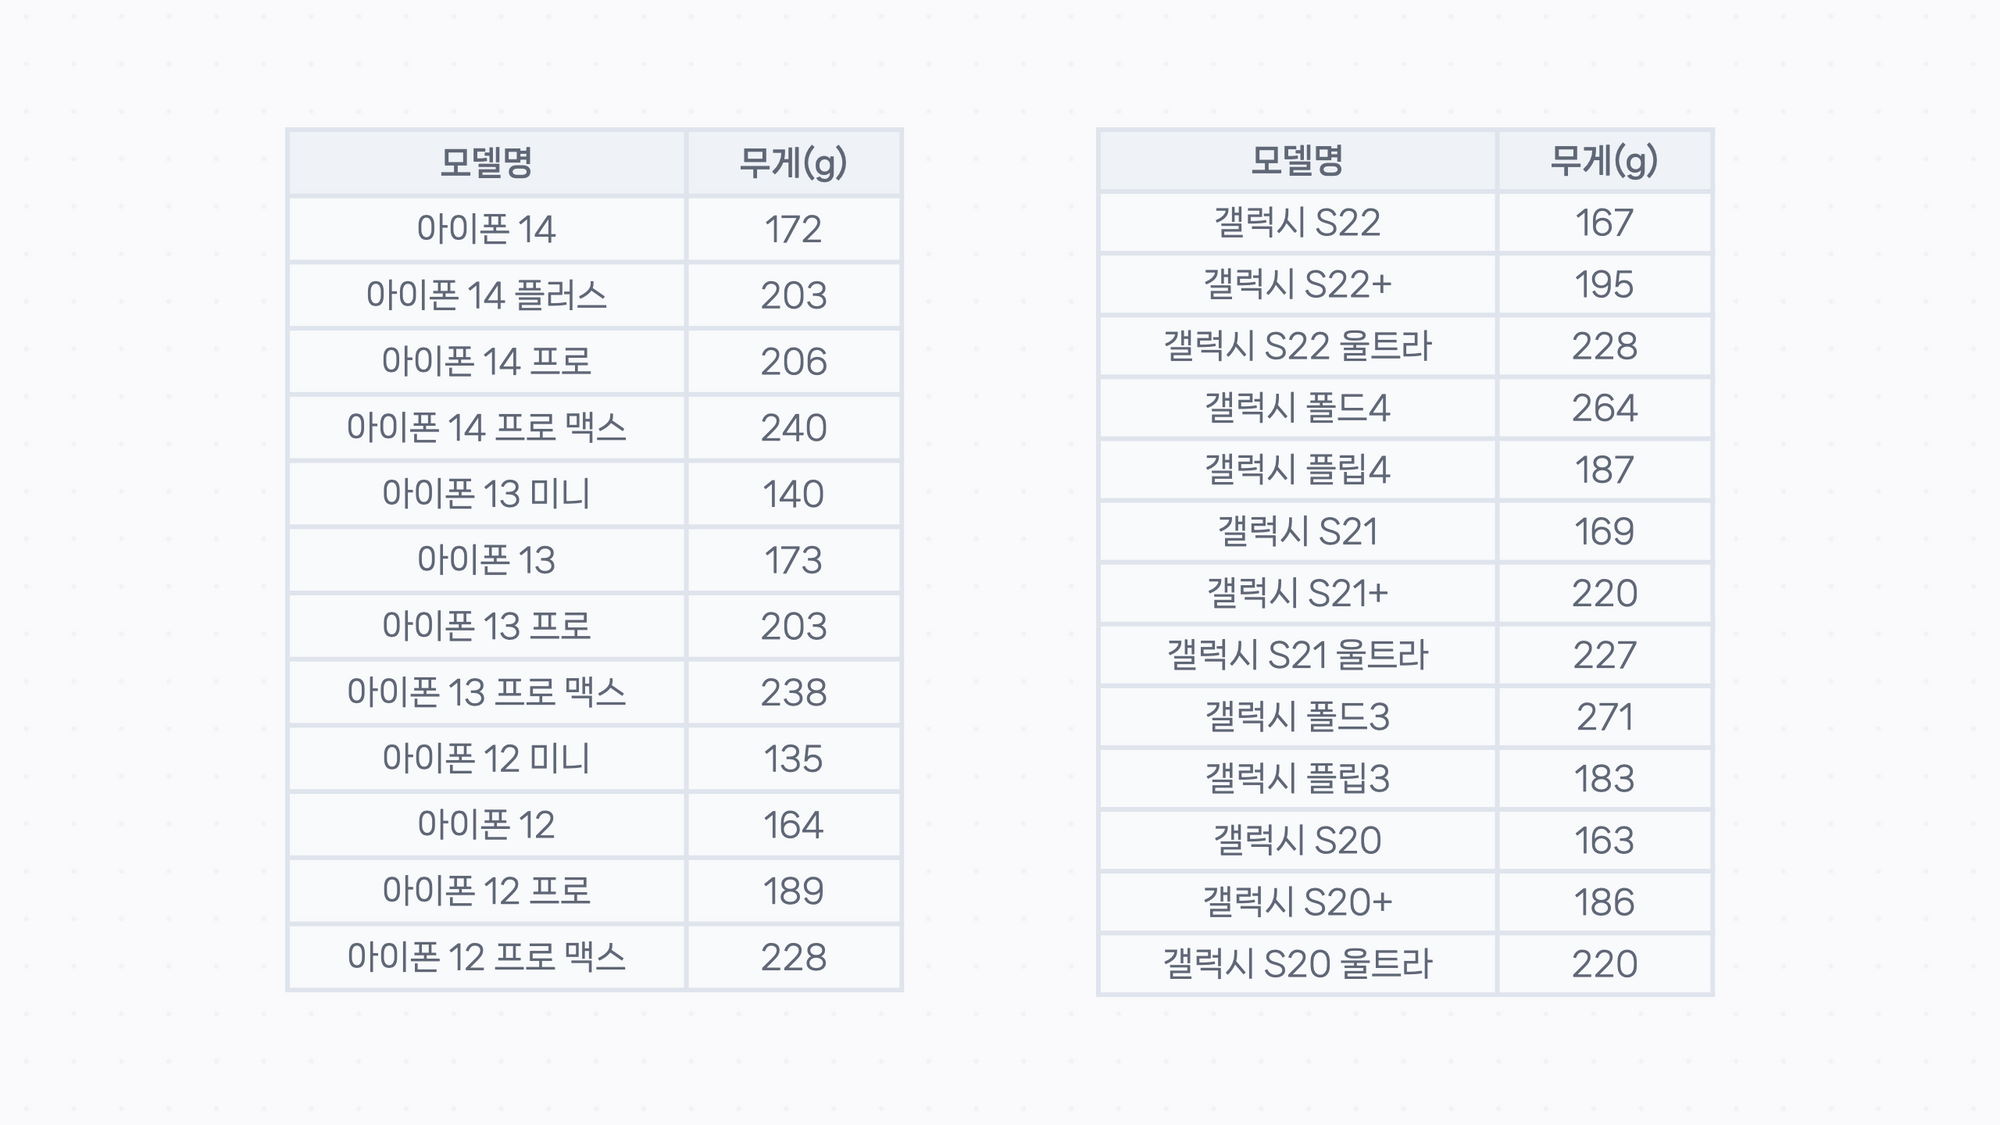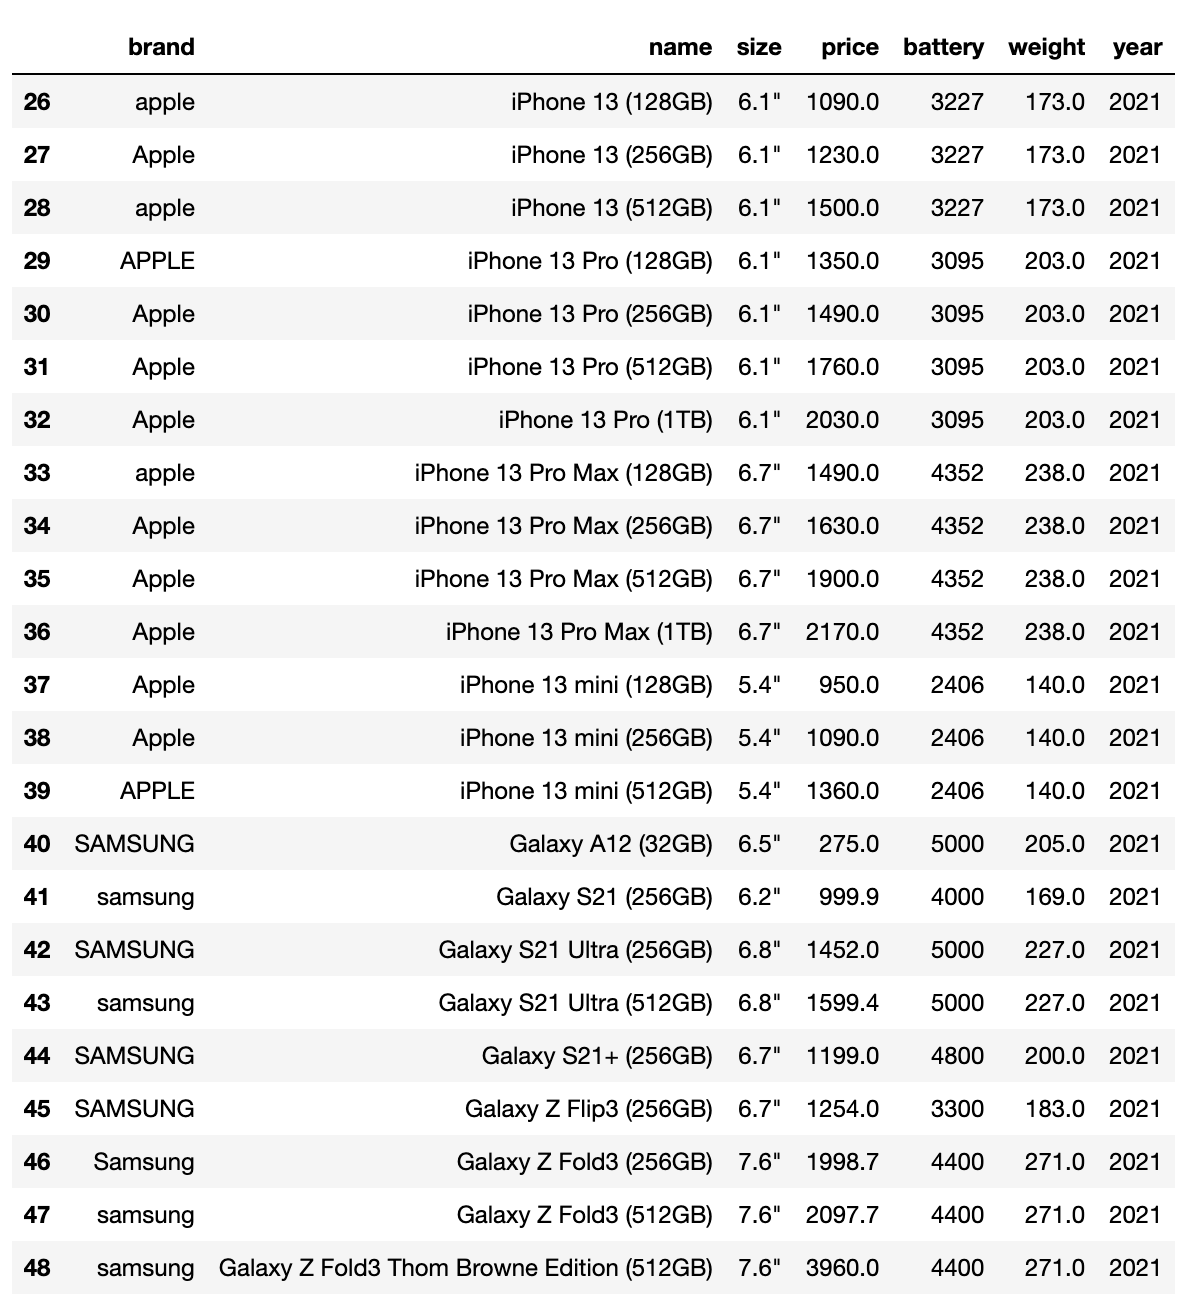

In [1]:
# pandas 불러오고 스마트폰 데이터 읽기
import pandas as pd

cellphone_df = pd.read_csv('../data/cellphone.csv')

In [2]:
# 전체 데이터 확인
cellphone_df

,brand,name,size,price,battery,weight,year
0,apple,iPhone 14 (128GB),"6.1""",1250.0,3729,172.0,2022
1,apple,iPhone 14 (256GB),"6.1""",1400.0,3729,172.0,2022
2,Apple,iPhone 14 (512GB),"6.1""",1700.0,3729,172.0,2022
3,apple,iPhone 14 Plus (128GB),"6.7""",1350.0,4325,203.0,2022
4,APPLE,iPhone 14 Plus (256GB),"6.7""",1500.0,4325,203.0,2022
...,...,...,...,...,...,...,...
65,SAMSUNG,Galaxy S20 Ultra (512GB),"6.9""",1793.0,5000,220.0,2020
66,samsung,Galaxy S20+ (256GB),"6.7""",1353.0,4500,186.0,2020
67,SAMSUNG,Galaxy Z Flip2 (256GB),"6.7""",1650.0,3300,183.0,2020
68,Samsung,Galaxy Z Fold2 (256GB),"7.6""",1892.0,4500,282.0,2020


In [3]:
# 열마다 결측값 개수 확인 → weight에만 결측값 3개
cellphone_df.isna().sum()

brand      0
name       0
size       0
price      0
battery    0
weight     3
year       0
dtype: int64

In [4]:
# weight가 비어 있는 행만 보기 → 누락된 모델 확인 (표 기준 무게 140g)
cellphone_df[cellphone_df['weight'].isna()]

,brand,name,size,price,battery,weight,year
37,Apple,iPhone 13 mini (128GB),"5.4""",950.0,2406,NaN,2021
38,Apple,iPhone 13 mini (256GB),"5.4""",1090.0,2406,NaN,2021
39,APPLE,iPhone 13 mini (512GB),"5.4""",1360.0,2406,NaN,2021


In [5]:
# 원본은 그대로 두고, 결측값 자리에 140이 들어가는지 mask로 미리 확인
mask = cellphone_df['weight'].isna()
cellphone_df['weight'].fillna(140)[mask]

37    140.0
38    140.0
39    140.0
Name: weight, dtype: float64

In [6]:
# weight 결측값 개수 다시 확인
cellphone_df['weight'].isna().sum()

np.int64(3)

In [7]:
# 결측값을 140으로 채워 원본에 저장하고, 결측값이 0개인지 확인
cellphone_df['weight'] = cellphone_df['weight'].fillna(140)
cellphone_df.isna().sum()

brand      0
name       0
size       0
price      0
battery    0
weight     0
year       0
dtype: int64

In [8]:
# 2021년에 출시한 스마트폰만 출력
cellphone_df[cellphone_df['year']==2021]

,brand,name,size,price,battery,weight,year
26,apple,iPhone 13 (128GB),"6.1""",1090.0,3227,173.0,2021
27,Apple,iPhone 13 (256GB),"6.1""",1230.0,3227,173.0,2021
28,apple,iPhone 13 (512GB),"6.1""",1500.0,3227,173.0,2021
29,APPLE,iPhone 13 Pro (128GB),"6.1""",1350.0,3095,203.0,2021
30,Apple,iPhone 13 Pro (256GB),"6.1""",1490.0,3095,203.0,2021
31,Apple,iPhone 13 Pro (512GB),"6.1""",1760.0,3095,203.0,2021
32,Apple,iPhone 13 Pro (1TB),"6.1""",2030.0,3095,203.0,2021
33,apple,iPhone 13 Pro Max (128GB),"6.7""",1490.0,4352,238.0,2021
34,Apple,iPhone 13 Pro Max (256GB),"6.7""",1630.0,4352,238.0,2021
35,Apple,iPhone 13 Pro Max (512GB),"6.7""",1900.0,4352,238.0,2021


# 실습 2
효준이가 스마트폰 데이터를 수집할 때 중복으로 여러 번 입력한 데이터가 몇 개 있다고 합니다. cellphone_df에서 중복값은 1개씩만 남기고 나머지는 삭제해 주세요. 참고로 중복으로 입력한 데이터는 모든 컬럼에 있는 값들이 똑같다고 합니다.

주의 사항: 채점을 위해 가장 마지막 줄에는 cellphone_df라고 입력해서 DataFrame을 출력해 주세요.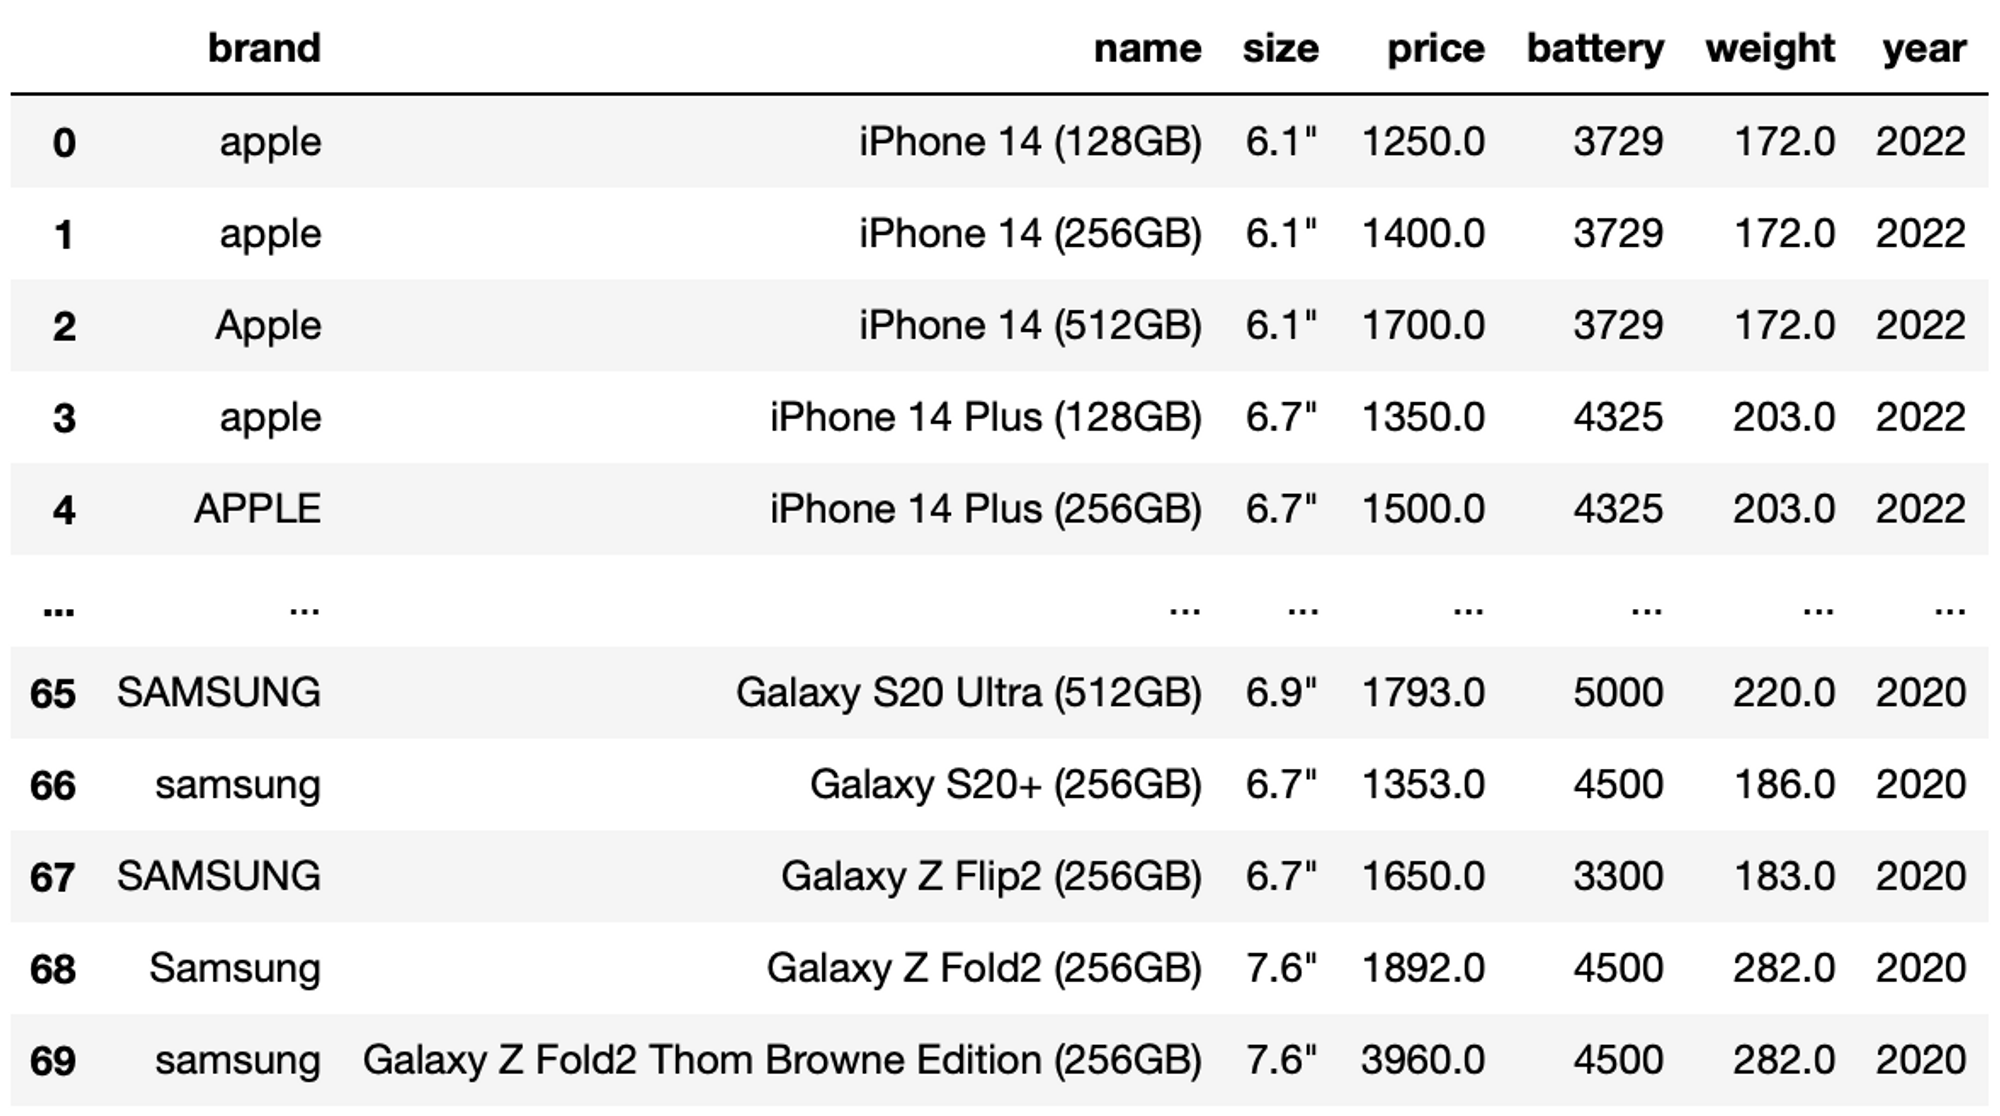

In [9]:
cellphone_df

,brand,name,size,price,battery,weight,year
0,apple,iPhone 14 (128GB),"6.1""",1250.0,3729,172.0,2022
1,apple,iPhone 14 (256GB),"6.1""",1400.0,3729,172.0,2022
2,Apple,iPhone 14 (512GB),"6.1""",1700.0,3729,172.0,2022
3,apple,iPhone 14 Plus (128GB),"6.7""",1350.0,4325,203.0,2022
4,APPLE,iPhone 14 Plus (256GB),"6.7""",1500.0,4325,203.0,2022
...,...,...,...,...,...,...,...
65,SAMSUNG,Galaxy S20 Ultra (512GB),"6.9""",1793.0,5000,220.0,2020
66,samsung,Galaxy S20+ (256GB),"6.7""",1353.0,4500,186.0,2020
67,SAMSUNG,Galaxy Z Flip2 (256GB),"6.7""",1650.0,3300,183.0,2020
68,Samsung,Galaxy Z Fold2 (256GB),"7.6""",1892.0,4500,282.0,2020


In [10]:
cellphone_df.duplicated().sum()

np.int64(4)

In [11]:
cellphone_df = cellphone_df.drop_duplicates()
cellphone_df

,brand,name,size,price,battery,weight,year
0,apple,iPhone 14 (128GB),"6.1""",1250.0,3729,172.0,2022
1,apple,iPhone 14 (256GB),"6.1""",1400.0,3729,172.0,2022
2,Apple,iPhone 14 (512GB),"6.1""",1700.0,3729,172.0,2022
3,apple,iPhone 14 Plus (128GB),"6.7""",1350.0,4325,203.0,2022
4,APPLE,iPhone 14 Plus (256GB),"6.7""",1500.0,4325,203.0,2022
...,...,...,...,...,...,...,...
65,SAMSUNG,Galaxy S20 Ultra (512GB),"6.9""",1793.0,5000,220.0,2020
66,samsung,Galaxy S20+ (256GB),"6.7""",1353.0,4500,186.0,2020
67,SAMSUNG,Galaxy Z Flip2 (256GB),"6.7""",1650.0,3300,183.0,2020
68,Samsung,Galaxy Z Fold2 (256GB),"7.6""",1892.0,4500,282.0,2020


# 실습 3
효준이는 스마트폰 구매 후보에서 가격이 너무 싸거나 비싼 건 제외하려고 합니다. cellphone_df에서 가격을 기준으로 이상점으로 볼 수 있는 데이터는 삭제해 주세요.

주의 사항: 채점을 위해 가장 마지막 줄에는 cellphone_df라고 입력해서 DataFrame을 출력해 주세요. 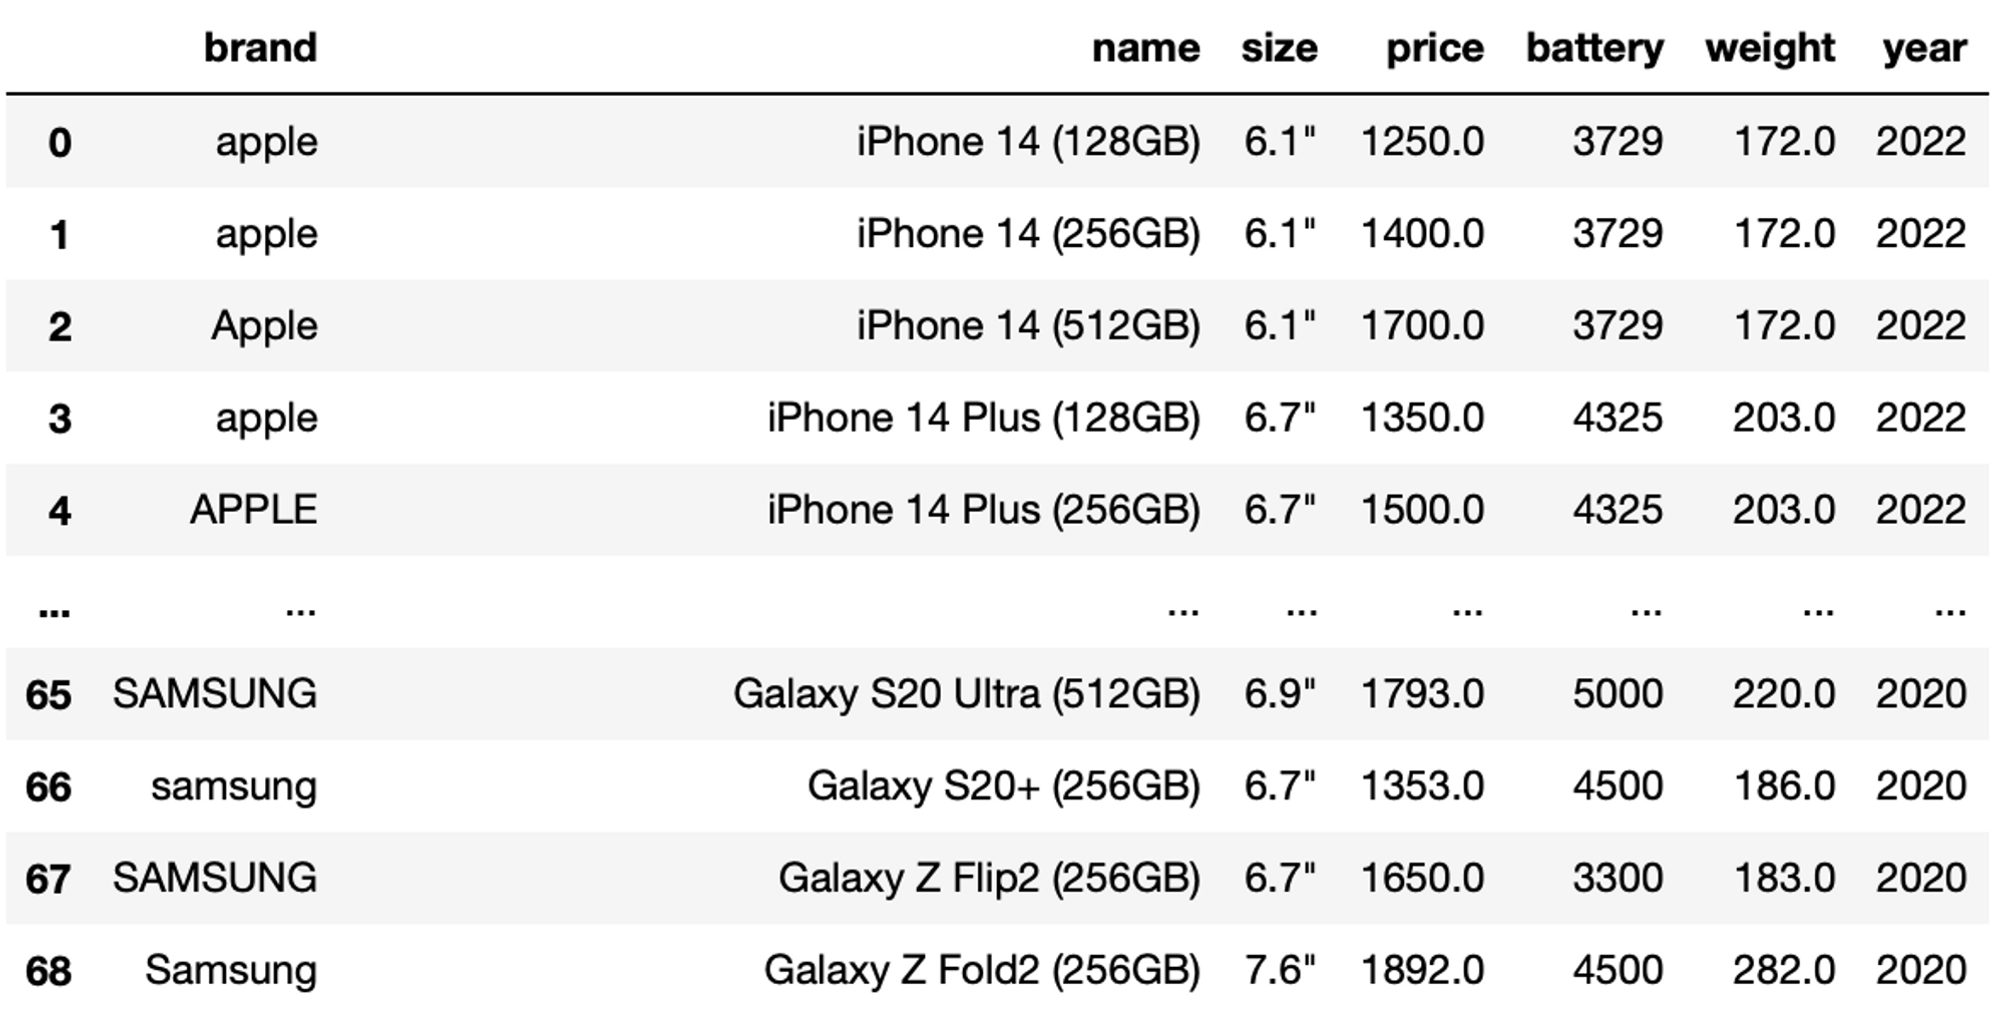

In [12]:
q1 = cellphone_df['price'].quantile(0.25)
q3 = cellphone_df['price'].quantile(0.75)

iqr = q3 - q1


In [13]:
lower_limit = q1 - 1.5*iqr
upper_limit = q3 + 1.5*iqr

In [14]:
condition1 = cellphone_df['price'] >= lower_limit
condition2 = cellphone_df['price'] <= upper_limit

In [15]:
cellphone_df[condition1 & condition2]

,brand,name,size,price,battery,weight,year
0,apple,iPhone 14 (128GB),"6.1""",1250.0,3729,172.0,2022
1,apple,iPhone 14 (256GB),"6.1""",1400.0,3729,172.0,2022
2,Apple,iPhone 14 (512GB),"6.1""",1700.0,3729,172.0,2022
3,apple,iPhone 14 Plus (128GB),"6.7""",1350.0,4325,203.0,2022
4,APPLE,iPhone 14 Plus (256GB),"6.7""",1500.0,4325,203.0,2022
...,...,...,...,...,...,...,...
64,samsung,Galaxy S20 Ultra (256GB),"6.9""",1595.0,5000,220.0,2020
65,SAMSUNG,Galaxy S20 Ultra (512GB),"6.9""",1793.0,5000,220.0,2020
66,samsung,Galaxy S20+ (256GB),"6.7""",1353.0,4500,186.0,2020
67,SAMSUNG,Galaxy Z Flip2 (256GB),"6.7""",1650.0,3300,183.0,2020


# 실습 4
실습 설명  
효준이가 수집한 핸드폰 데이터를 좀 더 사용하기 좋게 전처리해 봅시다. 아래에 쓰여 있는 대로 brand, name, size 컬럼에 있는 데이터를 가공해 주세요.

brand 컬럼에 저장된 제조사명의 대소문자 표기를 통일해 주세요. 첫 글자는 대문자로, 나머지 글자는 소문자로 바꿔 주시면 됩니다.
name 컬럼에는 iPhone 14 Pro (256GB)와 같이 스마트폰의 모델명(iPhone 14 Pro)과 용량(256GB) 정보가 함께 들어 있습니다. 모델과 용량을 쉽게 구분해서 볼 수 있도록 문자열을 분리해 주세요. 모델명은 model 컬럼, 용량은 capacity 컬럼에 저장하고, 기존의 name 컬럼은 삭제하면 됩니다. 모델명 앞뒤에 불필요한 공백 문자열이 없도록 처리하는 것도 잊지 마세요!
size 컬럼에는 스마트폰의 디스플레이 크기 정보가 담겨 있습니다. 그런데 데이터에 인치(inch)를 나타내는 " 기호가 들어 있어서 pandas가 이 컬럼의 데이터 타입을 문자 데이터로 인식하고 있네요. " 기호를 없앤 뒤 size 컬럼의 데이터 타입을 적절한 숫자 타입으로 바꿔 주세요.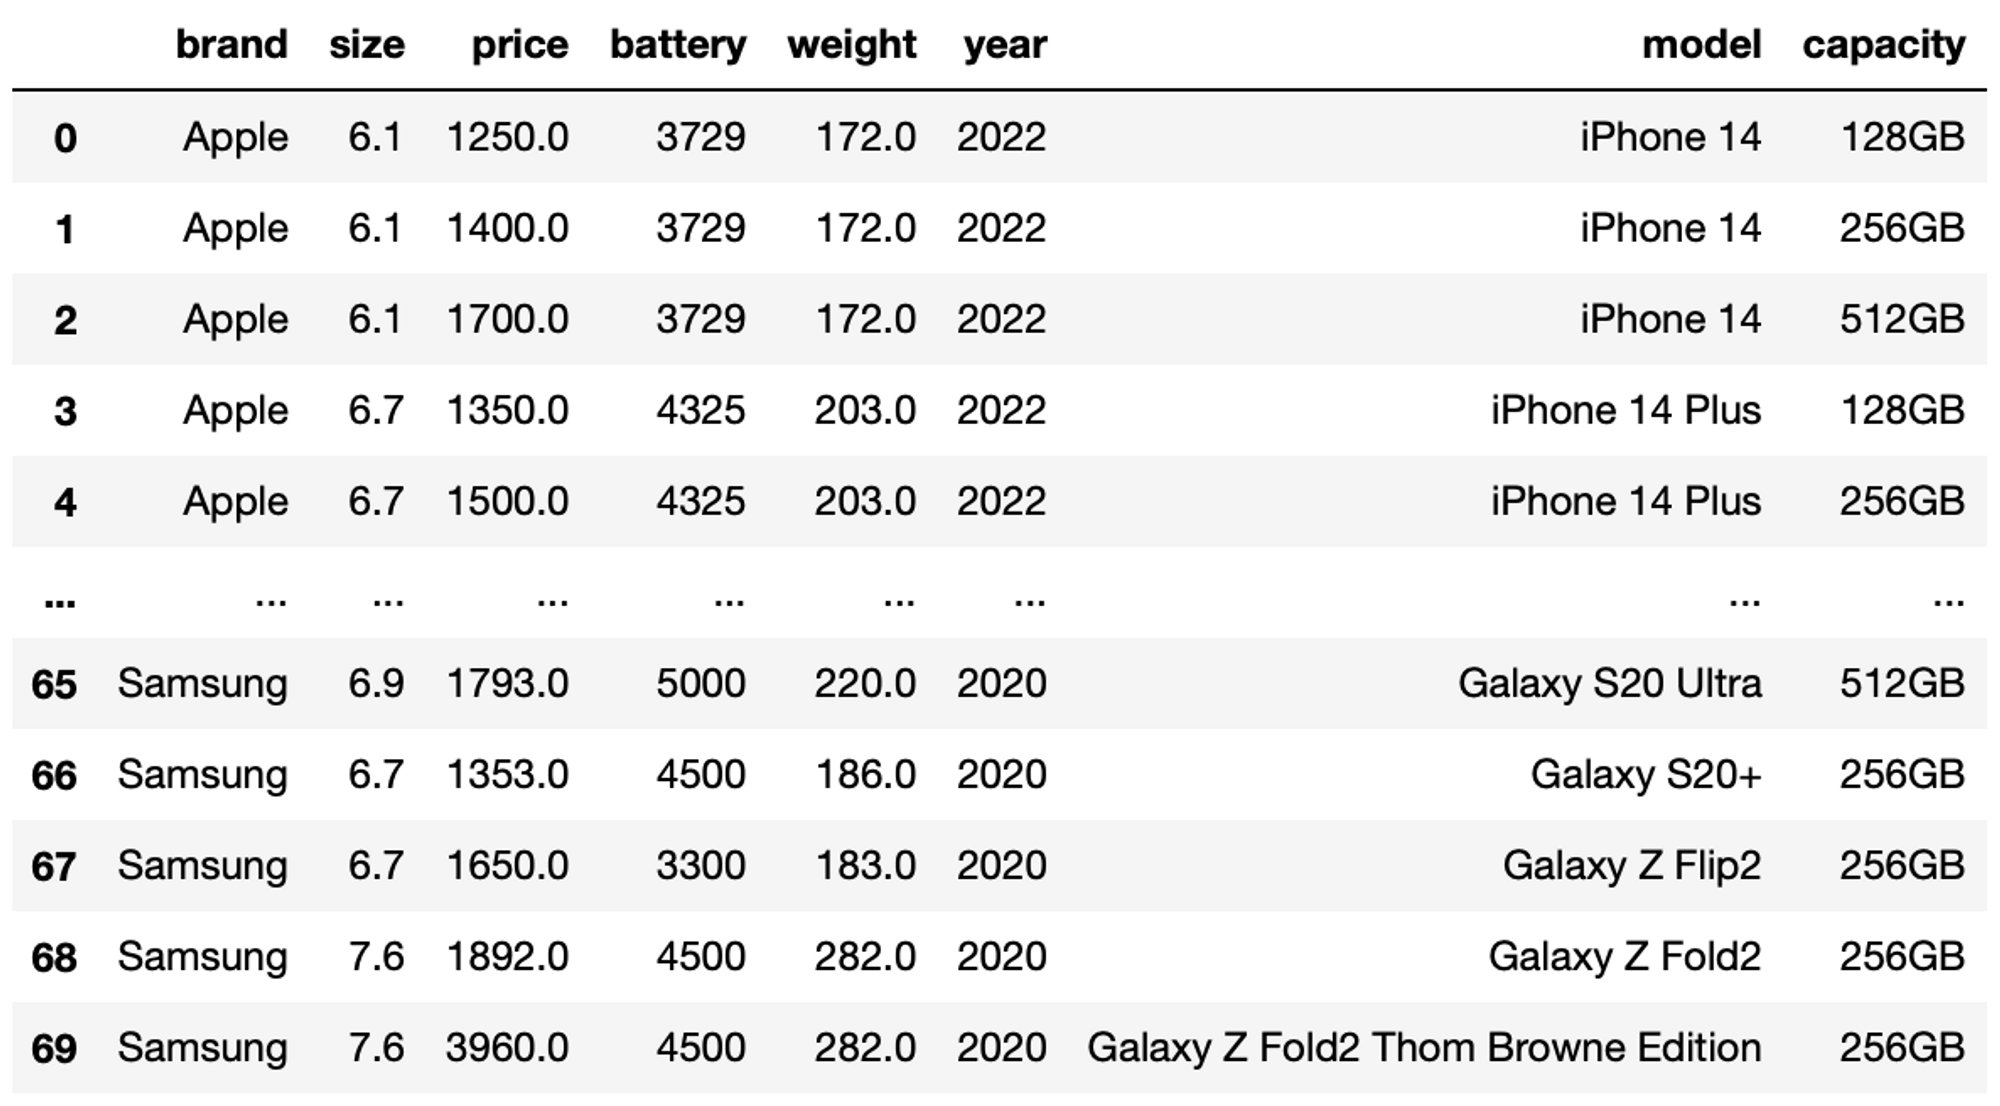

In [16]:
import pandas as pd

cellphone_df = pd.read_csv('../data/cellphone.csv')

In [17]:
cellphone_df

,brand,name,size,price,battery,weight,year
0,apple,iPhone 14 (128GB),"6.1""",1250.0,3729,172.0,2022
1,apple,iPhone 14 (256GB),"6.1""",1400.0,3729,172.0,2022
2,Apple,iPhone 14 (512GB),"6.1""",1700.0,3729,172.0,2022
3,apple,iPhone 14 Plus (128GB),"6.7""",1350.0,4325,203.0,2022
4,APPLE,iPhone 14 Plus (256GB),"6.7""",1500.0,4325,203.0,2022
...,...,...,...,...,...,...,...
65,SAMSUNG,Galaxy S20 Ultra (512GB),"6.9""",1793.0,5000,220.0,2020
66,samsung,Galaxy S20+ (256GB),"6.7""",1353.0,4500,186.0,2020
67,SAMSUNG,Galaxy Z Flip2 (256GB),"6.7""",1650.0,3300,183.0,2020
68,Samsung,Galaxy Z Fold2 (256GB),"7.6""",1892.0,4500,282.0,2020


In [18]:
cellphone_df['brand'] = cellphone_df['brand'].str.capitalize()
cellphone_df

,brand,name,size,price,battery,weight,year
0,Apple,iPhone 14 (128GB),"6.1""",1250.0,3729,172.0,2022
1,Apple,iPhone 14 (256GB),"6.1""",1400.0,3729,172.0,2022
2,Apple,iPhone 14 (512GB),"6.1""",1700.0,3729,172.0,2022
3,Apple,iPhone 14 Plus (128GB),"6.7""",1350.0,4325,203.0,2022
4,Apple,iPhone 14 Plus (256GB),"6.7""",1500.0,4325,203.0,2022
...,...,...,...,...,...,...,...
65,Samsung,Galaxy S20 Ultra (512GB),"6.9""",1793.0,5000,220.0,2020
66,Samsung,Galaxy S20+ (256GB),"6.7""",1353.0,4500,186.0,2020
67,Samsung,Galaxy Z Flip2 (256GB),"6.7""",1650.0,3300,183.0,2020
68,Samsung,Galaxy Z Fold2 (256GB),"7.6""",1892.0,4500,282.0,2020


In [19]:
parts = cellphone_df['name'].str.split('(')

In [20]:
cellphone_df['model'] = parts.str[0].str.strip()

In [21]:
cellphone_df['capacity'] = parts.str[1].str.replace(')','',regex=False)

In [22]:
cellphone_df = cellphone_df.drop(columns='name')
cellphone_df

,brand,size,price,battery,weight,year,model,capacity
0,Apple,"6.1""",1250.0,3729,172.0,2022,iPhone 14,128GB
1,Apple,"6.1""",1400.0,3729,172.0,2022,iPhone 14,256GB
2,Apple,"6.1""",1700.0,3729,172.0,2022,iPhone 14,512GB
3,Apple,"6.7""",1350.0,4325,203.0,2022,iPhone 14 Plus,128GB
4,Apple,"6.7""",1500.0,4325,203.0,2022,iPhone 14 Plus,256GB
...,...,...,...,...,...,...,...,...
65,Samsung,"6.9""",1793.0,5000,220.0,2020,Galaxy S20 Ultra,512GB
66,Samsung,"6.7""",1353.0,4500,186.0,2020,Galaxy S20+,256GB
67,Samsung,"6.7""",1650.0,3300,183.0,2020,Galaxy Z Flip2,256GB
68,Samsung,"7.6""",1892.0,4500,282.0,2020,Galaxy Z Fold2,256GB


In [23]:
cellphone_df['size'] = cellphone_df['size'].str.replace('"','',regex=False).astype(float)

In [24]:
cellphone_df

,brand,size,price,battery,weight,year,model,capacity
0,Apple,6.1,1250.0,3729,172.0,2022,iPhone 14,128GB
1,Apple,6.1,1400.0,3729,172.0,2022,iPhone 14,256GB
2,Apple,6.1,1700.0,3729,172.0,2022,iPhone 14,512GB
3,Apple,6.7,1350.0,4325,203.0,2022,iPhone 14 Plus,128GB
4,Apple,6.7,1500.0,4325,203.0,2022,iPhone 14 Plus,256GB
...,...,...,...,...,...,...,...,...
65,Samsung,6.9,1793.0,5000,220.0,2020,Galaxy S20 Ultra,512GB
66,Samsung,6.7,1353.0,4500,186.0,2020,Galaxy S20+,256GB
67,Samsung,6.7,1650.0,3300,183.0,2020,Galaxy Z Flip2,256GB
68,Samsung,7.6,1892.0,4500,282.0,2020,Galaxy Z Fold2,256GB
